In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [ ]:
df = pd.read_csv('/content/diabetes.csv')

In [ ]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.shape

(768, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


here , to check the missing values we see the 0 in each columns

In [ ]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
(df == 0).sum()

,0
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,500


In [ ]:
df['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


In [ ]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

In [ ]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

the testing data and training data is split

In [ ]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (614, 8)
Testing features: (154, 8)

Training target distribution:
Outcome
0    400
1    214
Name: count, dtype: int64

Testing target distribution:
Outcome
0    100
1     54
Name: count, dtype: int64


completing the missing values with median values


In [ ]:
from sklearn.impute import SimpleImputer

zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

# Replace invalid zeros with NaN
X_train[zero_columns] = X_train[zero_columns].replace(0, np.nan)
X_test[zero_columns] = X_test[zero_columns].replace(0, np.nan)

# Calculate medians from training data only
imputer = SimpleImputer(strategy='median')

X_train[zero_columns] = imputer.fit_transform(X_train[zero_columns])
X_test[zero_columns] = imputer.transform(X_test[zero_columns])

In [ ]:
print("Missing values in training data:")
print(X_train[zero_columns].isnull().sum())

print("\nMissing values in testing data:")
print(X_test[zero_columns].isnull().sum())

Missing values in training data:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Missing values in testing data:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining feature means (approximately 0):")
print(np.round(X_train.mean(axis=0), 2))

Training data shape: (614, 8)
Testing data shape: (154, 8)

Training feature means (approximately 0):
[-0. -0.  0. -0. -0.  0. -0. -0.]


In [ ]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
y_pred_dt = dt.predict(X_test)

In [ ]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Baseline Decision Tree Accuracy:", accuracy_dt)
print("Baseline Decision Tree Accuracy (%):", round(accuracy_dt * 100, 2))

Baseline Decision Tree Accuracy: 0.6818181818181818
Baseline Decision Tree Accuracy (%): 68.18


In [ ]:
from sklearn.ensemble import BaggingClassifier

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42
)

In [ ]:
bagging.fit(X_train, y_train)

BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                  n_estimators=100, random_state=42)

In [ ]:
y_pred_bagging = bagging.predict(X_test)

accuracy_bagging = accuracy_score(y_test, y_pred_bagging)

print("Bagging Accuracy:", accuracy_bagging)
print("Bagging Accuracy (%):", round(accuracy_bagging * 100, 2))

Bagging Accuracy: 0.7207792207792207
Bagging Accuracy (%): 72.08


In [ ]:
from sklearn.ensemble import AdaBoostClassifier

boosting = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

In [ ]:
boosting.fit(X_train, y_train)

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1,
                                                    random_state=42),
                   random_state=42)

In [ ]:
y_pred_boosting = boosting.predict(X_test)

accuracy_boosting = accuracy_score(y_test, y_pred_boosting)

print("AdaBoost Accuracy:", accuracy_boosting)
print("AdaBoost Accuracy (%):", round(accuracy_boosting * 100, 2))

AdaBoost Accuracy: 0.7467532467532467
AdaBoost Accuracy (%): 74.68


In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

In [ ]:
estimators = [
    ('dt', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=5)),
    ('lr', LogisticRegression(max_iter=1000, random_state=42))
]

stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=DecisionTreeClassifier(random_state=42),
    cv=5
)

In [ ]:
stacking.fit(X_train, y_train)

StackingClassifier(cv=5,
                   estimators=[('dt',
                                DecisionTreeClassifier(max_depth=5,
                                                       random_state=42)),
                               ('knn', KNeighborsClassifier()),
                               ('lr',
                                LogisticRegression(max_iter=1000,
                                                   random_state=42))],
                   final_estimator=DecisionTreeClassifier(random_state=42))

In [ ]:
y_pred_stacking = stacking.predict(X_test)

accuracy_stacking = accuracy_score(y_test, y_pred_stacking)

print("Stacking Accuracy:", accuracy_stacking)
print("Stacking Accuracy (%):", round(accuracy_stacking * 100, 2))

Stacking Accuracy: 0.6623376623376623
Stacking Accuracy (%): 66.23


In [ ]:
results = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Bagging',
        'AdaBoost',
        'Stacking'
    ],
    'Accuracy': [
        accuracy_dt,
        accuracy_bagging,
        accuracy_boosting,
        accuracy_stacking
    ]
})

results['Accuracy (%)'] = (results['Accuracy'] * 100).round(2)

results

,Model,Accuracy,Accuracy (%)
0,Decision Tree,0.681818,68.18
1,Bagging,0.720779,72.08
2,AdaBoost,0.746753,74.68
3,Stacking,0.662338,66.23


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
models = {
    'Decision Tree': y_pred_dt,
    'Bagging': y_pred_bagging,
    'AdaBoost': y_pred_boosting,
    'Stacking': y_pred_stacking
}

metrics = []

for name, y_pred in models.items():
    metrics.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

metrics_df = pd.DataFrame(metrics)

metrics_df = metrics_df.round(4)

metrics_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.6818,0.5532,0.4815,0.5149
1,Bagging,0.7208,0.6222,0.5185,0.5657
2,AdaBoost,0.7468,0.6596,0.5741,0.6139
3,Stacking,0.6623,0.5185,0.5185,0.5185


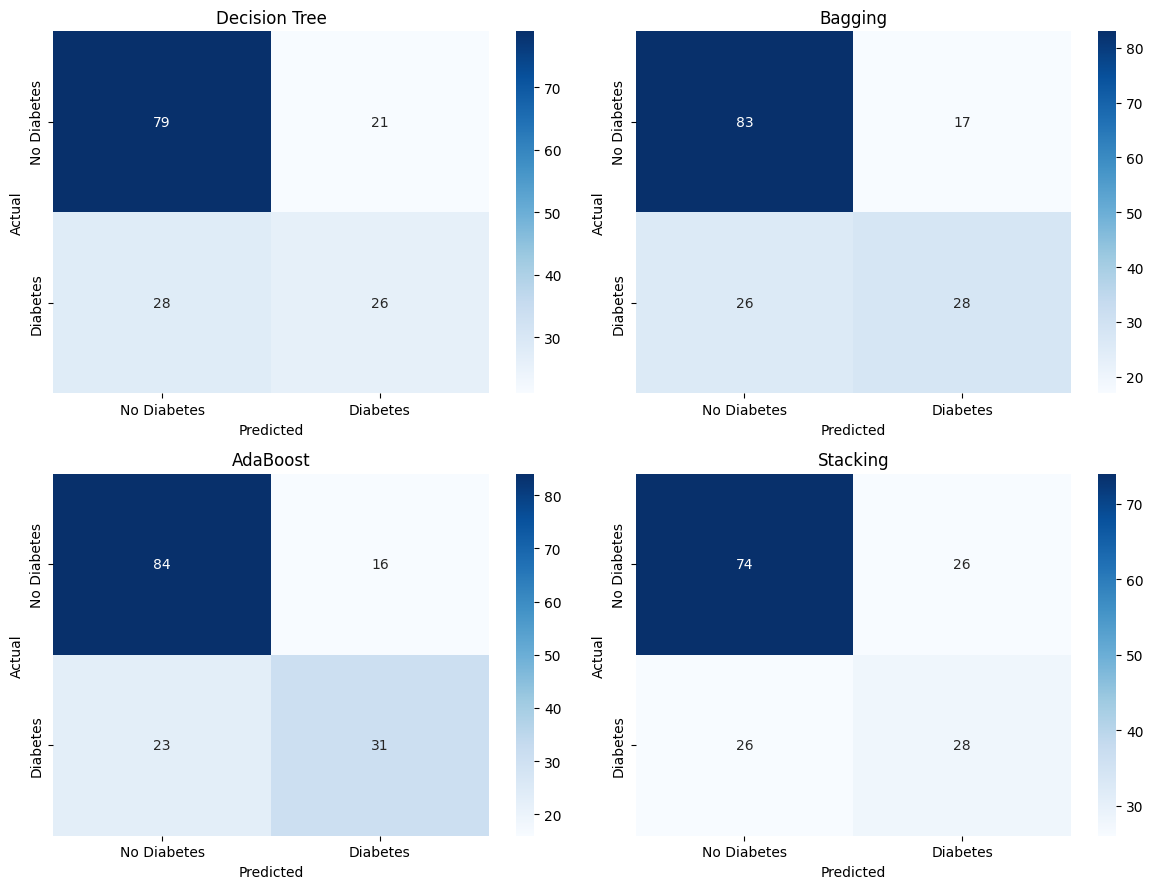

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, y_pred) in zip(axes.flat, models.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Diabetes', 'Diabetes'],
        yticklabels=['No Diabetes', 'Diabetes'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()